In [1]:
# Credit Scoring Model
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.0


In [21]:
from sklearn.datasets import fetch_openml

credit = fetch_openml("credit-g", version=1, as_frame=True)

df = credit.frame

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 21)


In [22]:
print(df.info)

<bound method DataFrame.info of     checking_status  duration                  credit_history  \
0                <0         6  critical/other existing credit   
1          0<=X<200        48                   existing paid   
2       no checking        12  critical/other existing credit   
3                <0        42                   existing paid   
4                <0        24              delayed previously   
..              ...       ...                             ...   
995     no checking        12                   existing paid   
996              <0        30                   existing paid   
997     no checking        12                   existing paid   
998              <0        45                   existing paid   
999        0<=X<200        45  critical/other existing credit   

                 purpose  credit_amount    savings_status  employment  \
0               radio/tv           1169  no known savings         >=7   
1               radio/tv           5951  

In [23]:
print(df.head)

<bound method NDFrame.head of     checking_status  duration                  credit_history  \
0                <0         6  critical/other existing credit   
1          0<=X<200        48                   existing paid   
2       no checking        12  critical/other existing credit   
3                <0        42                   existing paid   
4                <0        24              delayed previously   
..              ...       ...                             ...   
995     no checking        12                   existing paid   
996              <0        30                   existing paid   
997     no checking        12                   existing paid   
998              <0        45                   existing paid   
999        0<=X<200        45  critical/other existing credit   

                 purpose  credit_amount    savings_status  employment  \
0               radio/tv           1169  no known savings         >=7   
1               radio/tv           5951    

In [24]:
print(df.isnull().sum())

checking_status           0
duration                  0
credit_history            0
purpose                   0
credit_amount             0
savings_status            0
employment                0
installment_commitment    0
personal_status           0
other_parties             0
residence_since           0
property_magnitude        0
age                       0
other_payment_plans       0
housing                   0
existing_credits          0
job                       0
num_dependents            0
own_telephone             0
foreign_worker            0
class                     0
dtype: int64


In [25]:
print(df.describe(include="all"))

       checking_status     duration credit_history   purpose  credit_amount  \
count             1000  1000.000000           1000      1000    1000.000000   
unique               4          NaN              5        10            NaN   
top        no checking          NaN  existing paid  radio/tv            NaN   
freq               394          NaN            530       280            NaN   
mean               NaN    20.903000            NaN       NaN    3271.258000   
std                NaN    12.058814            NaN       NaN    2822.736876   
min                NaN     4.000000            NaN       NaN     250.000000   
25%                NaN    12.000000            NaN       NaN    1365.500000   
50%                NaN    18.000000            NaN       NaN    2319.500000   
75%                NaN    24.000000            NaN       NaN    3972.250000   
max                NaN    72.000000            NaN       NaN   18424.000000   

       savings_status employment  installment_commi

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   checking_status         1000 non-null   category
 1   duration                1000 non-null   int64   
 2   credit_history          1000 non-null   category
 3   purpose                 1000 non-null   category
 4   credit_amount           1000 non-null   int64   
 5   savings_status          1000 non-null   category
 6   employment              1000 non-null   category
 7   installment_commitment  1000 non-null   int64   
 8   personal_status         1000 non-null   category
 9   other_parties           1000 non-null   category
 10  residence_since         1000 non-null   int64   
 11  property_magnitude      1000 non-null   category
 12  age                     1000 non-null   int64   
 13  other_payment_plans     1000 non-null   category
 14  housing                 1000 non-nul

In [27]:
print(df["class"].value_counts(normalize=True) * 100)

class
good    70.0
bad     30.0
Name: proportion, dtype: float64


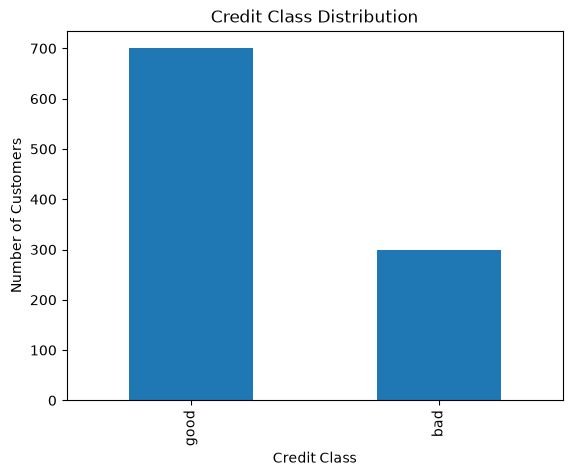

In [28]:
df["class"].value_counts().plot(kind="bar")

plt.title("Credit Class Distribution")
plt.xlabel("Credit Class")
plt.ylabel("Number of Customers")
plt.show()

In [29]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1000, 20)
Target shape: (1000,)


In [30]:
categorical_features = X.select_dtypes(include=["object", "category"]).columns
numerical_features = X.select_dtypes(include=["int64", "float64"]).columns

print("Categorical features:")
print(list(categorical_features))

print("\nNumerical features:")
print(list(numerical_features))

Categorical features:
['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Numerical features:
['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 20)
Testing data: (200, 20)


In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (800, 61)
Processed testing data shape: (200, 61)


In [35]:
#Import logistic regression. 
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
print("Logistic Regression model created successfully!")

Logistic Regression model created successfully!


In [36]:
#train the model. 
model.fit(X_train_processed, y_train)
print("Model trained successfully!")

Model trained successfully!


In [38]:
#make Predictions
y_pred = model.predict(X_test_processed)
print("Predictions generated successfully!")
print(y_pred[:10])

Predictions generated successfully!
['good' 'bad' 'bad' 'good' 'bad' 'good' 'good' 'good' 'bad' 'good']


In [39]:
#evalute the model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="bad")
recall = recall_score(y_test, y_pred, pos_label="bad")
f1 = f1_score(y_test, y_pred, pos_label="bad")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.705
Precision: 0.5094
Recall   : 0.45
F1-Score : 0.4779


In [40]:
#Classification report 
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         bad       0.51      0.45      0.48        60
        good       0.78      0.81      0.79       140

    accuracy                           0.70       200
   macro avg       0.64      0.63      0.64       200
weighted avg       0.70      0.70      0.70       200



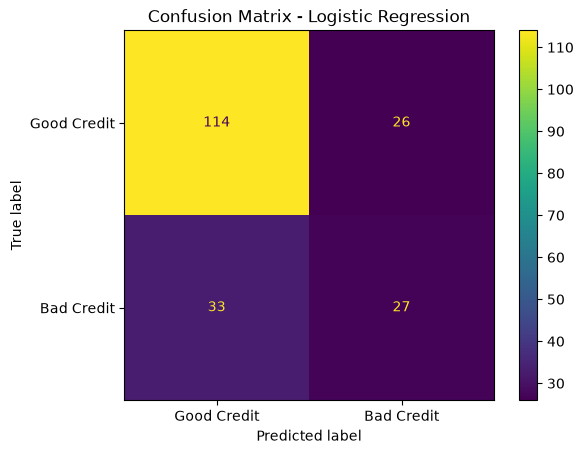

In [41]:
#Confusion matrix 
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["good", "bad"])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good Credit", "Bad Credit"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [42]:
#Import random forest. 
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [44]:
#Train random forest. 
rf_model.fit(X_train_processed, y_train)
print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [45]:
#Make a prediction. 
y_pred_rf = rf_model.predict(X_test_processed)

print("Random Forest predictions generated successfully!")
print(y_pred_rf[:10])

Random Forest predictions generated successfully!
['good' 'bad' 'good' 'good' 'good' 'good' 'good' 'good' 'bad' 'good']


In [46]:
#Evaluate random forest. 
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, pos_label="bad")
recall_rf = recall_score(y_test, y_pred_rf, pos_label="bad")
f1_rf = f1_score(y_test, y_pred_rf, pos_label="bad")

print("Accuracy :", round(accuracy_rf, 4))
print("Precision:", round(precision_rf, 4))
print("Recall   :", round(recall_rf, 4))
print("F1-Score :", round(f1_rf, 4))

Accuracy : 0.765
Precision: 0.6667
Recall   : 0.4333
F1-Score : 0.5253


In [47]:
#Classification report 
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

         bad       0.67      0.43      0.53        60
        good       0.79      0.91      0.84       140

    accuracy                           0.77       200
   macro avg       0.73      0.67      0.68       200
weighted avg       0.75      0.77      0.75       200



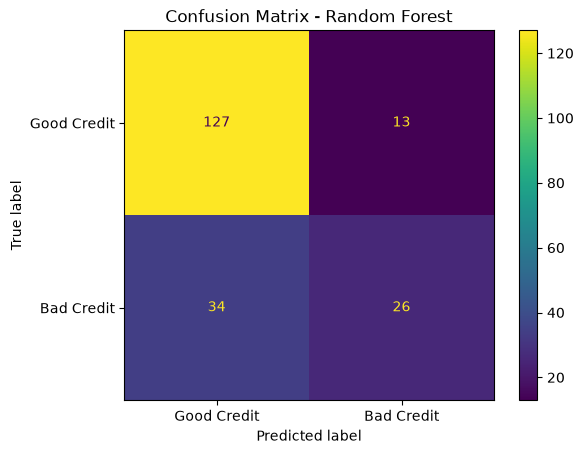

In [48]:
#Confusion matrix 
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=["good", "bad"])

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Good Credit", "Bad Credit"]
)

disp_rf.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

In [49]:
#Compare both models. 
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, accuracy_rf],
    "Precision": [precision, precision_rf],
    "Recall": [recall, recall_rf],
    "F1-Score": [f1, f1_rf]
})

print(comparison)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression     0.705   0.509434  0.450000  0.477876
1        Random Forest     0.765   0.666667  0.433333  0.525253


In [50]:
#ROC-AUC
from sklearn.metrics import roc_auc_score

# Probability of the "bad" class
y_prob_lr = model.predict_proba(X_test_processed)[:, list(model.classes_).index("bad")]
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, list(rf_model.classes_).index("bad")]

auc_lr = roc_auc_score((y_test == "bad").astype(int), y_prob_lr)
auc_rf = roc_auc_score((y_test == "bad").astype(int), y_prob_rf)

print("Logistic Regression ROC-AUC:", round(auc_lr, 4))
print("Random Forest ROC-AUC:", round(auc_rf, 4))

Logistic Regression ROC-AUC: 0.7594
Random Forest ROC-AUC: 0.7999


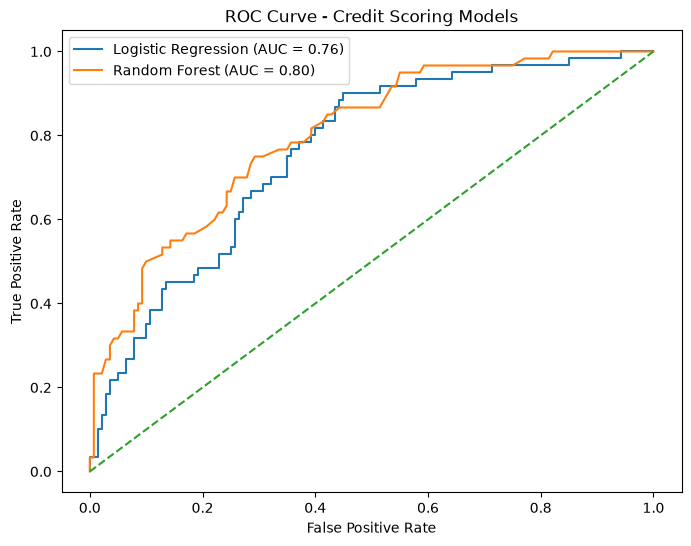

In [52]:
#ROC Curve
from sklearn.metrics import roc_curve

y_test_binary = (y_test == "bad").astype(int)

fpr_lr, tpr_lr, _ = roc_curve(y_test_binary, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test_binary, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {auc_lr:.2f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc_rf:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Credit Scoring Models")
plt.legend()
plt.show()

In [53]:
#Random forest feature importance 
feature_names = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(15))

                                              Feature  Importance
55                           numerical__credit_amount    0.099735
54                                numerical__duration    0.083557
58                                     numerical__age    0.074605
3            categorical__checking_status_no checking    0.050957
57                         numerical__residence_since    0.035086
1                     categorical__checking_status_<0    0.034195
56                  numerical__installment_commitment    0.032827
21                   categorical__savings_status_<100    0.021788
5   categorical__credit_history_critical/other exi...    0.020210
13                       categorical__purpose_new car    0.018924
41              categorical__other_payment_plans_none    0.016888
59                        numerical__existing_credits    0.016839
0               categorical__checking_status_0<=X<200    0.016459
29    categorical__personal_status_female div/dep/mar    0.015830
15        

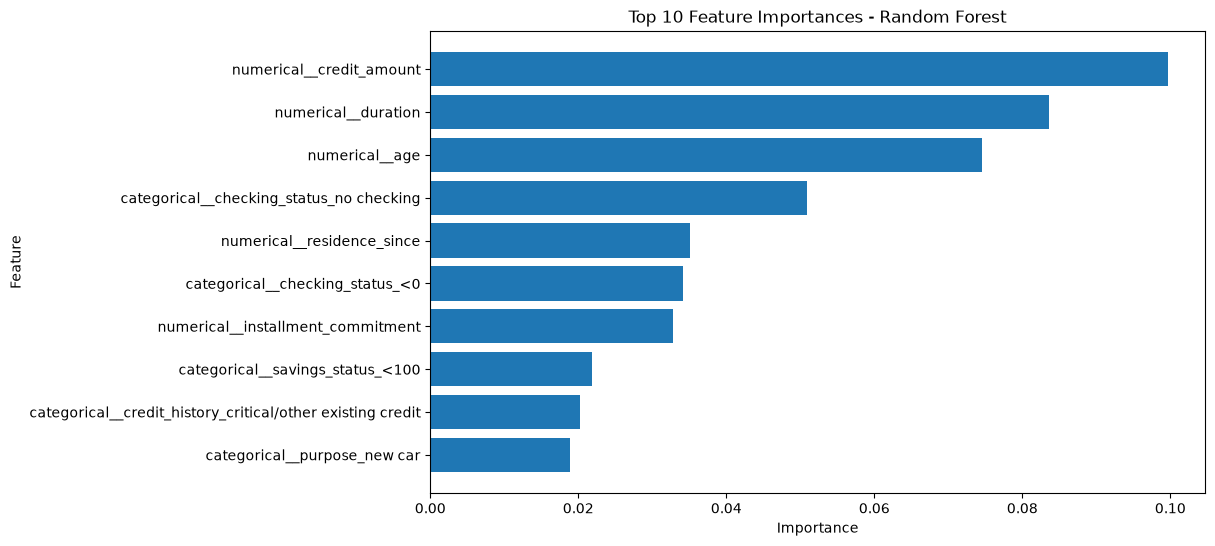

In [54]:
top_features = importance.head(10)

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances - Random Forest")
plt.show()

In [55]:
#Save the trend model. 
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(rf_model, "credit_scoring_model.pkl")

print("Preprocessor saved successfully!")
print("Credit scoring model saved successfully!")

Preprocessor saved successfully!
Credit scoring model saved successfully!


In [58]:
# Example prediction using one test customer

sample_customer = X_test.iloc[[0]]

prediction = rf_model.predict(
    preprocessor.transform(sample_customer)
)

print("Predicted Credit Risk:", prediction[0])
print("Actual Credit Class:", y_test.iloc[0])

Predicted Credit Risk: good
Actual Credit Class: good


In [59]:
print("========== CREDIT SCORING MODEL ==========")

print("\nDataset:")
print("German Credit Dataset")
print("Total records:", len(df))
print("Total features:", X.shape[1])

print("\nModels:")
print("1. Logistic Regression")
print("2. Random Forest")

print("\nPerformance:")
print("Logistic Regression Accuracy:", round(accuracy, 4))
print("Random Forest Accuracy:", round(accuracy_rf, 4))

print("\nROC-AUC:")
print("Logistic Regression:", round(auc_lr, 4))
print("Random Forest:", round(auc_rf, 4))

print("\nSample Prediction:")
print("Predicted:", prediction[0])
print("Actual:", y_test.iloc[0])

print("\nModel files saved:")
print("preprocessor.pkl")
print("credit_scoring_model.pkl")

print("\n========== PROJECT COMPLETED ==========")

========== CREDIT SCORING MODEL ==========

Dataset:
German Credit Dataset
Total records: 1000
Total features: 20

Models:
1. Logistic Regression
2. Random Forest

Performance:
Logistic Regression Accuracy: 0.705
Random Forest Accuracy: 0.765

ROC-AUC:
Logistic Regression: 0.7594
Random Forest: 0.7999

Sample Prediction:
Predicted: good
Actual: good

Model files saved:
preprocessor.pkl
credit_scoring_model.pkl

========== PROJECT COMPLETED ==========
